In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

1. Carga los datos y genera un dataFrame que excluya las columnas correspondientes
a la abreviatura del país, código de llamada, capital, código de moneda, ciudad más
grande, lenguaje oficial, latitud y longitud. Considerando estos datos, realiza una
inspección inicial sobre ellos, considerando gráficos. Concluye.


In [19]:
pd.set_option('display.max_columns', None)
df=pd.read_csv('world-data-2023.csv')

In [20]:
df= df.drop(columns=['Abbreviation','Calling Code','Capital/Major City',
                     'Currency-Code','Largest city','Official language','Latitude','Longitude'])

In [21]:
df.head()

,Country,Density\n(P/Km2),Agricultural Land( %),Land Area(Km2),Armed Forces size,Birth Rate,Co2-Emissions,CPI,CPI Change (%),Fertility Rate,Forested Area (%),Gasoline Price,GDP,Gross primary education enrollment (%),Gross tertiary education enrollment (%),Infant mortality,Life expectancy,Maternal mortality ratio,Minimum wage,Out of pocket health expenditure,Physicians per thousand,Population,Population: Labor force participation (%),Tax revenue (%),Total tax rate,Unemployment rate,Urban_population
0,Afghanistan,60,58.10%,"652,230","323,000",32.49,"8,672",149.9,2.30%,4.47,2.10%,$0.70,"$19,101,353,833",104.00%,9.70%,47.9,64.5,638.0,$0.43,78.40%,0.28,"38,041,754",48.90%,9.30%,71.40%,11.12%,"9,797,273"
1,Albania,105,43.10%,"28,748","9,000",11.78,"4,536",119.05,1.40%,1.62,28.10%,$1.36,"$15,278,077,447",107.00%,55.00%,7.8,78.5,15.0,$1.12,56.90%,1.20,"2,854,191",55.70%,18.60%,36.60%,12.33%,"1,747,593"
2,Algeria,18,17.40%,"2,381,741","317,000",24.28,"150,006",151.36,2.00%,3.02,0.80%,$0.28,"$169,988,236,398",109.90%,51.40%,20.1,76.7,112.0,$0.95,28.10%,1.72,"43,053,054",41.20%,37.20%,66.10%,11.70%,"31,510,100"
3,Andorra,164,40.00%,468,NaN,7.20,469,NaN,NaN,1.27,34.00%,$1.51,"$3,154,057,987",106.40%,NaN,2.7,NaN,NaN,$6.63,36.40%,3.33,"77,142",NaN,NaN,NaN,NaN,"67,873"
4,Angola,26,47.50%,"1,246,700","117,000",40.73,"34,693",261.73,17.10%,5.52,46.30%,$0.97,"$94,635,415,870",113.50%,9.30%,51.6,60.8,241.0,$0.71,33.40%,0.21,"31,825,295",77.50%,9.20%,49.10%,6.89%,"21,061,025"


In [22]:
print(f'La cantidad de duplicados es de: {df.duplicated().sum()}') # Verificación de filas duplicadas


La cantidad de duplicados es de: 0


In [23]:
print(df.dtypes) # Ver tipos de datos

Country                                          str
Density\n(P/Km2)                                 str
Agricultural Land( %)                            str
Land Area(Km2)                                   str
Armed Forces size                                str
Birth Rate                                   float64
Co2-Emissions                                    str
CPI                                              str
CPI Change (%)                                   str
Fertility Rate                               float64
Forested Area (%)                                str
Gasoline Price                                   str
GDP                                              str
Gross primary education enrollment (%)           str
Gross tertiary education enrollment (%)          str
Infant mortality                             float64
Life expectancy                              float64
Maternal mortality ratio                     float64
Minimum wage                                  

In [24]:
for columna in df.columns:  # Transformar de columnas str numericos y eliminar caracteres especiales
    if columna != 'Country':
        df[columna] = (
            df[columna].astype(str)
            .str.replace(',', '', regex=False)
            .str.replace('$', '', regex=False)
            .str.replace('%', '', regex=False)
        )

        df[columna] = pd.to_numeric(df[columna],errors='coerce')

In [25]:
print(df.dtypes)
df.isna().sum().sort_values(ascending=False)

Country                                          str
Density\n(P/Km2)                               int64
Agricultural Land( %)                        float64
Land Area(Km2)                               float64
Armed Forces size                            float64
Birth Rate                                   float64
Co2-Emissions                                float64
CPI                                          float64
CPI Change (%)                               float64
Fertility Rate                               float64
Forested Area (%)                            float64
Gasoline Price                               float64
GDP                                          float64
Gross primary education enrollment (%)       float64
Gross tertiary education enrollment (%)      float64
Infant mortality                             float64
Life expectancy                              float64
Maternal mortality ratio                     float64
Minimum wage                                 f

Minimum wage                                 45
Tax revenue (%)                              26
Armed Forces size                            24
Gasoline Price                               20
Population: Labor force participation (%)    19
Unemployment rate                            19
CPI                                          17
CPI Change (%)                               16
Maternal mortality ratio                     14
Gross tertiary education enrollment (%)      12
Total tax rate                               12
Life expectancy                               8
Out of pocket health expenditure              7
Gross primary education enrollment (%)        7
Physicians per thousand                       7
Co2-Emissions                                 7
Agricultural Land( %)                         7
Forested Area (%)                             7
Fertility Rate                                7
Infant mortality                              6
Birth Rate                              

In [26]:
df.describe()

,Density\n(P/Km2),Agricultural Land( %),Land Area(Km2),Armed Forces size,Birth Rate,Co2-Emissions,CPI,CPI Change (%),Fertility Rate,Forested Area (%),Gasoline Price,GDP,Gross primary education enrollment (%),Gross tertiary education enrollment (%),Infant mortality,Life expectancy,Maternal mortality ratio,Minimum wage,Out of pocket health expenditure,Physicians per thousand,Population,Population: Labor force participation (%),Tax revenue (%),Total tax rate,Unemployment rate,Urban_population
count,195.000000,188.000000,1.940000e+02,1.710000e+02,189.000000,1.880000e+02,178.000000,179.000000,188.000000,188.000000,175.000000,1.930000e+02,188.000000,183.000000,189.000000,187.000000,181.000000,150.000000,188.000000,188.000000,1.940000e+02,176.000000,169.000000,183.000000,176.000000,1.900000e+02
mean,356.764103,39.117553,6.896244e+05,1.592749e+05,20.214974,1.777992e+05,190.460955,6.722346,2.698138,32.015426,1.002457,4.772959e+11,102.470213,37.963388,21.332804,72.279679,160.392265,2.194133,32.637234,1.839840,3.938116e+07,62.738068,16.573964,40.822404,6.886364,2.230454e+07
std,1982.888967,21.783052,1.921609e+06,3.806288e+05,9.945774,8.387903e+05,397.947380,24.450414,1.282267,23.791331,0.368858,2.172173e+12,13.151607,29.261022,19.548058,7.483661,233.502024,2.970796,19.172697,1.684261,1.450924e+08,10.502907,6.961632,20.557662,5.079216,7.543050e+07
min,2.000000,0.600000,0.000000e+00,0.000000e+00,5.900000,1.100000e+01,99.030000,-4.300000,0.980000,0.000000,0.000000,4.727146e+07,23.400000,0.800000,1.400000,52.800000,2.000000,0.010000,0.200000,0.010000,8.360000e+02,38.000000,0.000000,8.000000,0.090000,5.464000e+03
25%,35.500000,21.700000,2.382825e+04,1.100000e+04,11.300000,2.304250e+03,113.885000,1.000000,1.705000,11.000000,0.755000,8.454620e+09,98.950000,12.150000,6.000000,67.000000,13.000000,0.402500,17.450000,0.332500,1.962678e+06,56.150000,11.700000,30.600000,3.395000,1.152961e+06
50%,89.000000,39.600000,1.195110e+05,3.100000e+04,17.950000,1.230300e+04,125.340000,2.300000,2.245000,32.000000,0.980000,3.438723e+10,102.550000,31.200000,14.000000,73.200000,53.000000,1.045000,30.700000,1.460000,8.826588e+06,62.450000,16.300000,37.200000,5.360000,4.678104e+06
75%,216.500000,55.375000,5.242560e+05,1.420000e+05,28.750000,6.388425e+04,157.265000,4.250000,3.597500,48.175000,1.240000,2.340940e+11,108.025000,63.150000,32.700000,77.500000,186.000000,2.447500,43.975000,2.935000,2.858549e+07,69.500000,21.100000,48.000000,9.490000,1.490324e+07
max,26337.000000,82.600000,1.709824e+07,3.031000e+06,46.080000,9.893038e+06,4583.710000,254.900000,6.910000,98.300000,2.000000,2.142770e+13,142.500000,136.600000,84.500000,85.400000,1150.000000,13.590000,81.600000,8.420000,1.397715e+09,86.800000,37.200000,219.600000,28.180000,8.429340e+08


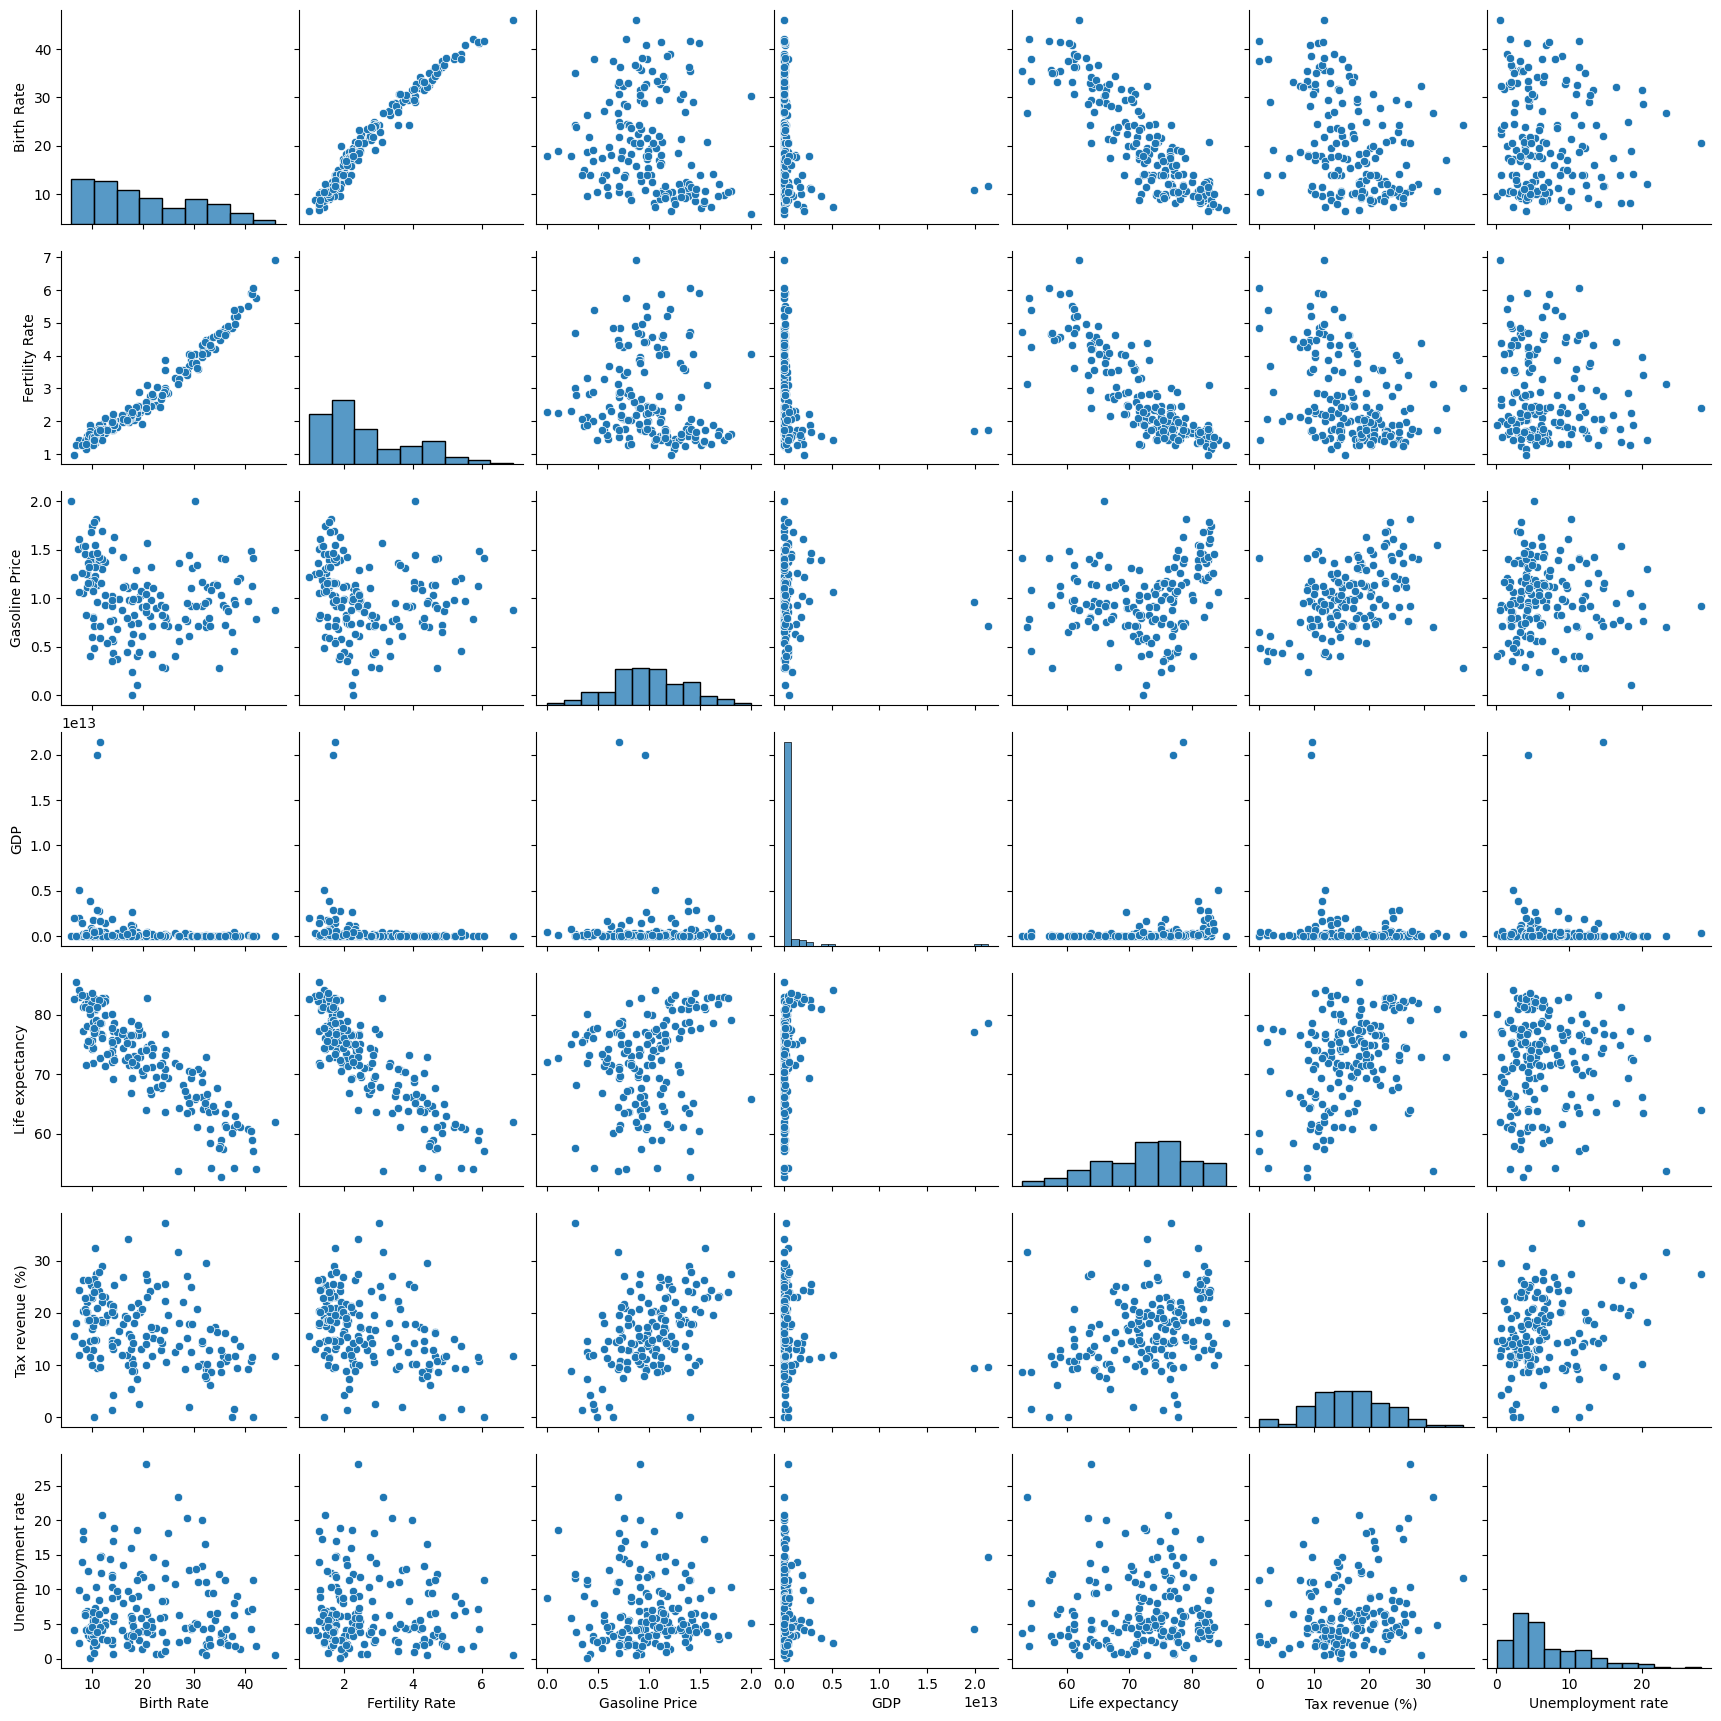

In [27]:
# Utilizo pairplot para ciertas columnas, para no saturar la grafica.
columnas_pairplot = ['Birth Rate','Fertility Rate','Gasoline Price','GDP','Life expectancy','Tax revenue (%)','Unemployment rate']
sns.pairplot(df[columnas_pairplot])
plt.show()


In [28]:
# A partir de la inspección inicial se observa la presencia de valores
# nulos en distintas columnas, siendo Minimun wage la columna con la mayor cantidad, además de múltiples columnas que
# requirieron ser transformadas desde texto a formato numérico para permitir su análisis.

# Por su parte, histogramas muestran distribuciones heterogéneas, observándose algunos indicadores (GDP) relativamente concentrados
# y otros con una mayor dispersión.

# Asimismo, en los gráficos de dispersión se identifican tanto relaciones positivas como negativas entre algunas variables,
# mientras que otras no presentan patrones evidentes.

# Finalmente, se aprecia que variables como GDP y Population poseen escalas considerablemente mayores que el resto,
# lo que dificulta su comparación visual directa con otros indicadores.

2. De las variables codificadas numéricamente, ¿hay pares de ellas en la que parezca
haber correlación? ¿Para cuál(es) de ellas se observa más claramente?

In [29]:
# Se observa una fuerte correlación positiva entre Birth Rate y Fertility Rate, siendo la relación más evidente del conjunto de datos.
# Además, se aprecia una correlación negativa entre Birth Rate y Life Expectancy, así como entre Fertility Rate y Life Expectancy.
# Estas relaciones sugieren que los países con mayores tasas de natalidad y fertilidad tienden a presentar menores expectativa de vida.

# También se aprecia una posible correlación positiva entre Gasoline Price y Tax Revenue (%),
# aunque con una dispersión considerablemente mayor que la observada en los pares anteriores.

3. Considera los dos pares de variables anteriores y elimina en cada caso los faltantes
y atípicos. Justifica en cada caso tu procedimiento

In [30]:
#Birth Rate - Fertility Rate, Gasoline Price - Tax Revenue(%)
# Cada una de estas columnas contiene valores nulos a tratar
df_filtrado = df.dropna(subset=['Birth Rate','Fertility Rate','Gasoline Price','Tax revenue (%)'])
df_filtrado[['Birth Rate','Fertility Rate','Gasoline Price','Tax revenue (%)']].isna().sum()

Birth Rate         0
Fertility Rate     0
Gasoline Price     0
Tax revenue (%)    0
dtype: int64

In [31]:
# limpieza de atípicos
def filtrar_atipicos(columna):
    Q1 = columna.quantile(0.25)
    Q3 = columna.quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    condicion = (columna >= lim_inf) & (columna <= lim_sup)
    return condicion

In [32]:
# Posteriormente se eliminan valores atípicos mediante el criterio
# de rango intercuartílico (IQR), conservando únicamente las
# observaciones dentro de los límites establecidos.
df_sin_atipicos = df_filtrado[
    filtrar_atipicos(df_filtrado['Birth Rate']) &
    filtrar_atipicos(df_filtrado['Fertility Rate']) &
    filtrar_atipicos(df_filtrado['Gasoline Price']) &
    filtrar_atipicos(df_filtrado['Tax revenue (%)'])
]

In [33]:
print('Filas originales:', len(df))
print('Sin nulos:', len(df_filtrado))
print('Sin atípicos:', len(df_sin_atipicos))

Filas originales: 195
Sin nulos: 155
Sin atípicos: 153


<Axes: ylabel='Gasoline Price'>

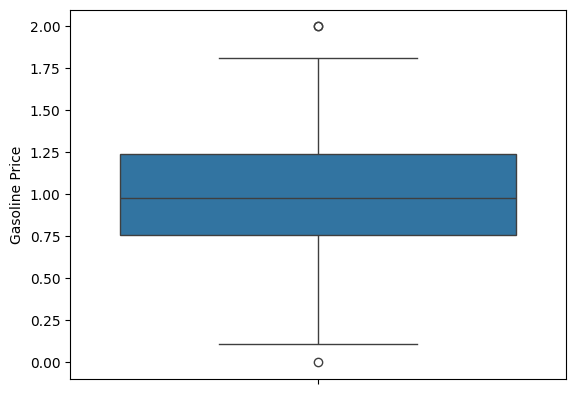

In [52]:
sns.boxplot(df['Gasoline Price'])

4. Construye un gráfico para verificar la correlación entre estas variables, ahora con los
datos preparados. Compara con lo obtenido anteriormente.


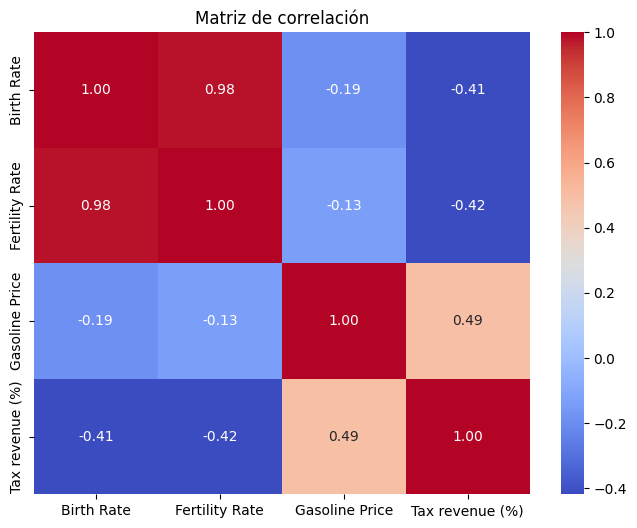

In [35]:
correlacion= df_sin_atipicos[['Birth Rate','Fertility Rate','Gasoline Price','Tax revenue (%)']].corr()
plt.figure(figsize=(8,6))

sns.heatmap(
    correlacion,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de correlación')
plt.show()

In [36]:
# Se confirma la fuerte correlacion positiva entre birth rate y fertility rate que es de un 98%
# Por su parte, la correlacion entre el precio de la gasolina y tax revenue es de 49%,
# es decir que no es una correlacion lo suficientemente fuerte como para afirmar una dependencia directa entre estas variables.

# Ademas, se observan correlaciones negativas moderadas entre Tax Revenue (%) y las tasas de natalidad y fertilidad.
# No obstante, esta relación podría ser espuria o estar explicada por otras variables asociadas al nivel
# de desarrollo económico de los países.


5. Realiza lo mismo para comparar la cantidad de médicos por cada mil personas y la
esperanza de vida. ¿Qué puedes concluir?



In [37]:
df_filtrado_2 = df.dropna(subset=['Life expectancy','Physicians per thousand'])
df_filtrado_2[['Life expectancy','Physicians per thousand']].isna().sum()

Life expectancy            0
Physicians per thousand    0
dtype: int64

In [38]:
df_sin_atipicos_2 = df_filtrado_2[
    filtrar_atipicos(df_filtrado_2['Life expectancy']) &
    filtrar_atipicos(df_filtrado_2['Physicians per thousand'])]

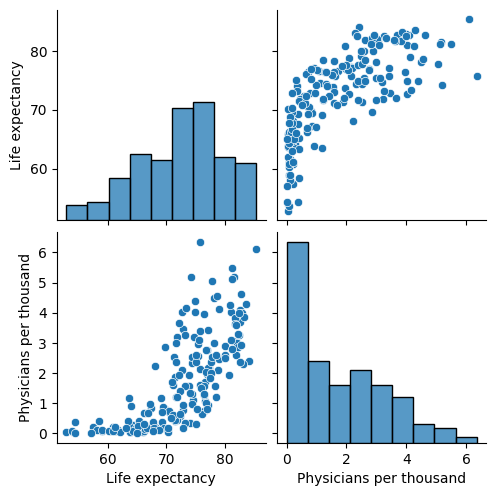

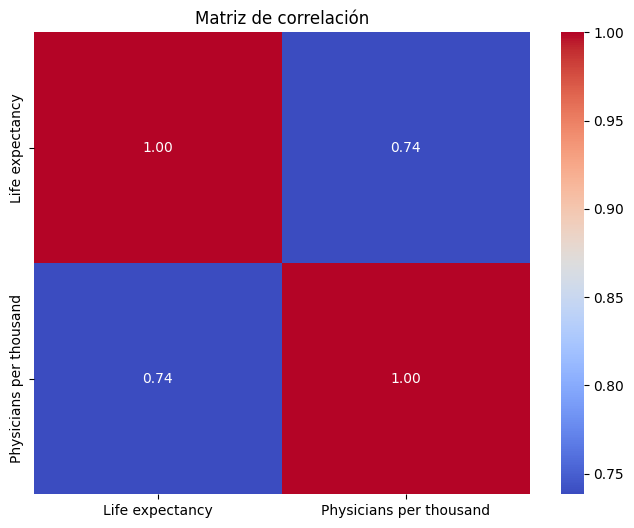

In [39]:
sns.pairplot(df_sin_atipicos_2[['Life expectancy','Physicians per thousand']])

correlacion= df_sin_atipicos_2[['Life expectancy','Physicians per thousand']].corr()
plt.figure(figsize=(8,6))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de correlación')
plt.show()

In [40]:
# El gráfico de dispersión sugiere que existe una relación positiva entre la cantidad de médicos por cada mil habitantes y la expectativa de vida.

# Se observa que, en países con menos de un médico por cada mil personas, la expectativa de vida rara vez supera los 70 años. 
# En cambio, a medida que la disponibilidad de médicos aumenta por sobre este umbral, la expectativa de vida tiende a incrementarse de forma significativa.
# Esta tendencia es consistente con el coeficiente de correlación obtenido (74%), lo que indica una relación positiva fuerte entre ambas variables.

# Respecto de las distribuciones, la mayor parte de los países presenta entre 0 y 1 médico por cada mil habitantes, 
# observándose una disminución progresiva en la frecuencia a medida que este indicador aumenta.

# Por otro lado, la expectativa de vida se concentra principalmente entre los 65 y 80 años, con una mayor densidad de observaciones cercana a los 70 años.

6. Construye un gráfico para representar la población total de los países y su producto
interno bruto. Prepara los datos y escoge el gráfico adecuado (si es necesario, limpia
y/o transforma los datos). Justifica.


In [41]:
df[['Population','GDP']].isna().sum()

Population    1
GDP           2
dtype: int64

In [42]:
df_filtrado_3 = df.dropna(subset=['Population','GDP'])
df_filtrado_3[['Population','GDP']].isna().sum()

Population    0
GDP           0
dtype: int64

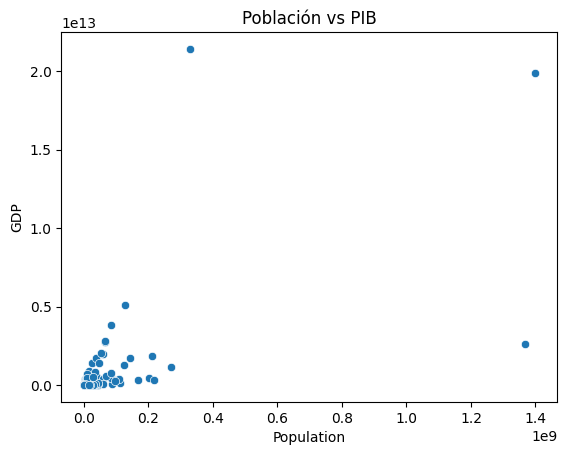

In [43]:
sns.scatterplot(data=df_filtrado_3, x='Population', y='GDP')
plt.title('Población vs PIB')
plt.xlabel('Population')
plt.ylabel('GDP')

plt.show()

In [44]:
df_filtrado_3['Population_log'] = np.log10(df_filtrado_3['Population'])
df_filtrado_3['GDP_log'] = np.log10(df_filtrado_3['GDP'])

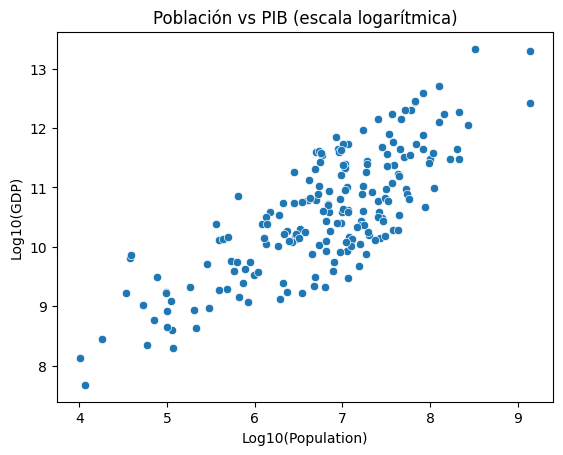

In [45]:
sns.scatterplot(data=df_filtrado_3, x='Population_log', y='GDP_log')

plt.title('Población vs PIB (escala logarítmica)')
plt.xlabel('Log10(Population)')
plt.ylabel('Log10(GDP)')

plt.show()

In [46]:
# Previamente se realizó una limpieza de las variables Population y GDP, corrigiendo su estructura para permitir el análisis numérico.
# Se eliminaron símbolos como "$" presentes en GDP y separadores de miles como "," presentes en diversas columnas, incluyendo Population.

# Posteriormente se construyó un gráfico de dispersión para analizar la relación entre ambas variables. 
# Al utilizar los valores originales, se observó una fuerte concentración de países en la zona inferior del gráfico,
# mientras que otro países ocupaban espacios extremos en el gráfico.

# Debido esto ultimo, se aplicó una transformación logarítmica en las variables para reducir los extremos, 
# comprimir los datos e identificar patrones.

# La relación entre Population y GDP se aprecia con mayor claridad, observándose una tendencia positiva que sugiere que 
# los países con mayores poblaciones tienden a presentar mayores niveles de producto interno bruto.

# Aunque existe una relación positiva entre población y PIB, otros factores también pueden influir en el tamaño de una economía.

7. Escoge otro par de datos, límpialos, prepáralos y analiza su posible relación. Justifica
utilizando las herramientas vistas y gráficos adecuados.


In [47]:
df[['Maternal mortality ratio','Infant mortality']].isna().sum()

Maternal mortality ratio    14
Infant mortality             6
dtype: int64

In [48]:
df_filtrado_4 = df.dropna(subset=['Maternal mortality ratio','Infant mortality'])

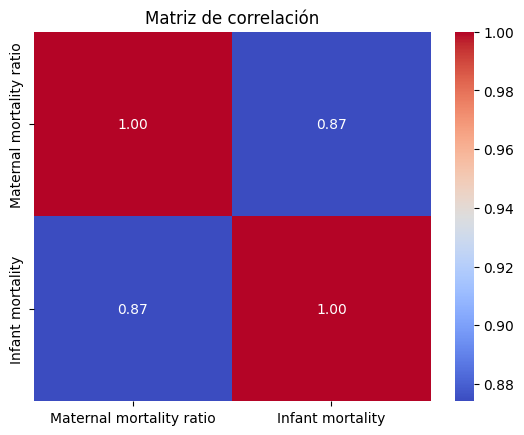

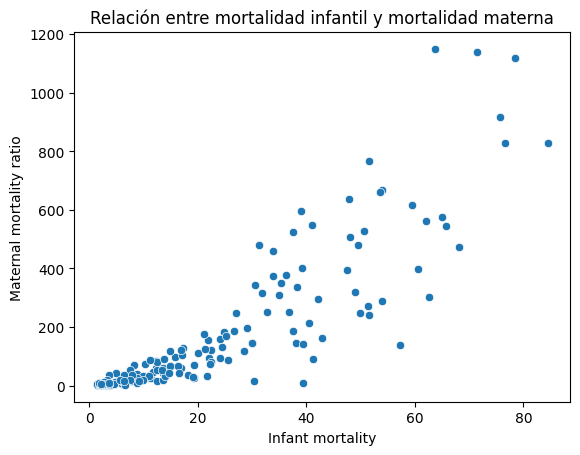

In [49]:
corr_p7=df_filtrado_4[['Maternal mortality ratio','Infant mortality']].corr()
sns.heatmap(corr_p7,annot=True, cmap='coolwarm',fmt='.2f')
plt.title('Matriz de correlación')
plt.show()
sns.scatterplot(data=df_filtrado_4,x='Infant mortality',y='Maternal mortality ratio')
plt.title('Relación entre mortalidad infantil y mortalidad materna')
plt.xlabel('Infant mortality')
plt.ylabel('Maternal mortality ratio')
plt.show()

In [50]:
# Se seleccionó un gráfico de dispersión debido a que permite visualizar la relación entre dos variables cuantitativas continuas.
# Previamente se eliminaron los registros con valores faltantes para asegurar la consistencia del análisis.

# Se observa una correlación positiva (87%) entre la mortalidad materna y la mortalidad infantil. En general, los países con mayores tasas
# de mortalidad materna tienden también a presentar mayores niveles de mortalidad infantil.

# Esto podría estar asociado a diferencias en el acceso y calidad de los sistemas de salud, aunque la correlación observada no implica
# necesariamente una relación causal directa.